In [73]:
using StatsBase, DataFrames, Plots, Distributions, Combinatorics, PrettyTables, FreqTables, Crayons
gr()

Plots.GRBackend()

In [5]:
using Dates
Dates.format(now(), "E, dd U yyyy HH:MM:SS")

"Saturday, 31 October 2026 09:04:25"

# Distribuciones Muestrales

Las medidas que se calculan sobre una población se llaman **parámetros** y las que se calculan sobre una muestra se llaman **Estadísticos** o **Estadígrafos**. Para los parámetros usamos letras griegas y para los estadísticos letras latinas.


|                     |  Población |  Muestra  |
|:-------------------:|:----------:|:---------:|
|        media        |    $\mu$   | $\bar{X}$ |
|       varianza      | $\sigma^2$ |   $S^2$   |
| desviación estándar |  $\sigma$  |    $S$    |
|      proporción     |    $\pi$   |    $p$    |
|        tamaño       |    $N$     |    $n$    |


**Parámetros**: son las características de la población, son generalmente desconocidos

**Estadísticos o Estadígrafos**: son funciones de los valores muestral


En la práctica se saca una muestra representativa de la población para hacer **inferencia estadística**.

La muestra debe ser obtenida al azar o aleatoriamente, significa, que todo elemento de la población tiene la misma probabilidad de ser elegido. 

**Inferencia**: sacar conclusiones para toda la población a partir de una muestra.



## Fórmulas

Sea una población conformada por: $X_1,X_2,\cdots,X_N$, se tiene:

$$ \mu=\frac{1}{N}\sum_{i=1}^{N}X_i $$
$$ \sigma^2=\frac{1}{N}\sum_{i=1}^{N}(X_i-\mu)^2 $$
$$ \pi=\frac{X\text{: número de items de interés}}{N} $$

Sea una muestra conformada por: $x_1,x_2,\cdots,x_n$, se tiene:

$$\bar{X}=\frac{1}{n}\sum_{i=1}^{n}x_i$$
$$S^2=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{X})^2$$
$$p=\frac{x\text{: número de items de interés}}{n}$$


Vamos a sacar todas las muestras posibles sin orden y sin reemplazo de un tamaño dado. Cada muestra tendrá su media y se conformará una población de medias. De igual manera sacaremos todas las varianzas muestrales y todas las proporciones muestrales.

## Ejercicio

Sea la población: 1,2,3,4,5 (notas de una evaluación) y obtengamos todas las muestras de tamaño 2 sin orden y sin reemplazo.

## Cálculo de los parámetros

In [6]:
Pob = [1,2,3,4,5] # notas
μ = mean(Pob)


3.0

In [7]:
σ² = var(Pob, corrected=false)

2.0

In [8]:
σ = std(Pob, corrected=false)

1.4142135623730951

In [9]:
N = length(Pob)


5

Para la proporción interesa los que tengan nota $\ge 3$

In [10]:
Pob[Pob .≥ 3]

3-element Vector{Int64}:
 3
 4
 5

In [11]:
π = length(Pob[Pob .≥ 3])/N

0.6

## Muestras

Obtengamos las muestras de tamaño 2. Salen $\binom{5}{2}=10$.

In [12]:
n = 2
muestras = collect(combinations(Pob, n)) 

10-element Vector{Vector{Int64}}:
 [1, 2]
 [1, 3]
 [1, 4]
 [1, 5]
 [2, 3]
 [2, 4]
 [2, 5]
 [3, 4]
 [3, 5]
 [4, 5]

In [13]:
medias_m = mean.(muestras)

10-element Vector{Float64}:
 1.5
 2.0
 2.5
 3.0
 2.5
 3.0
 3.5
 3.5
 4.0
 4.5

In [14]:
varianzas_m = var.(muestras, corrected=true)

10-element Vector{Float64}:
 0.5
 2.0
 4.5
 8.0
 0.5
 2.0
 4.5
 0.5
 2.0
 0.5

In [15]:
prop_m = sum.([muestras[i].≥ 3 for i in 1:10])/n

10-element Vector{Float64}:
 0.0
 0.5
 0.5
 0.5
 0.5
 0.5
 0.5
 1.0
 1.0
 1.0

In [75]:
dfm = DataFrame(muestras=muestras, medias_m=medias_m, varianzas_m=varianzas_m, prop_m=prop_m)
pretty_table(dfm)# header_crayon = crayon"red bold")

┌───────────────┬──────────┬─────────────┬─────────┐
│      muestras │ medias_m │ varianzas_m │  prop_m │
│ Vector{Int64} │  Float64 │     Float64 │ Float64 │
├───────────────┼──────────┼─────────────┼─────────┤
│        [1, 2] │      1.5 │         0.5 │     0.0 │
│        [1, 3] │      2.0 │         2.0 │     0.5 │
│        [1, 4] │      2.5 │         4.5 │     0.5 │
│        [1, 5] │      3.0 │         8.0 │     0.5 │
│        [2, 3] │      2.5 │         0.5 │     0.5 │
│        [2, 4] │      3.0 │         2.0 │     0.5 │
│        [2, 5] │      3.5 │         4.5 │     0.5 │
│        [3, 4] │      3.5 │         0.5 │     1.0 │
│        [3, 5] │      4.0 │         2.0 │     1.0 │
│        [4, 5] │      4.5 │         0.5 │     1.0 │
└───────────────┴──────────┴─────────────┴─────────┘


Las medias de las tres últimas columnas son:

In [17]:
mt = mean.(eachcol(select(dfm,2:4)))

3-element Vector{Float64}:
 3.0
 2.5
 0.6

Las varianzas de las tres útimas columnas son:

In [18]:
vt = var.(eachcol(select(dfm,2:4)), corrected=false)

3-element Vector{Float64}:
 0.75
 5.5
 0.09000000000000001

Distribución de frecuencias de las medias muestrales:

In [65]:
dft = select(dfm, Not(:muestras))
tm=freqtable(dft, :medias_m)
m = collect(1.5:0.5:4.5)
data = hcat(m,tm)
header = ["Medias muestrales", "Frecuencia"]
pretty_table(data) #,header=header,header_crayon=crayon"yellow bold",alignment=[:c,:c])

┌────────┬────────┐
│ Col. 1 │ Col. 2 │
├────────┼────────┤
│    1.5 │    1.0 │
│    2.0 │    1.0 │
│    2.5 │    2.0 │
│    3.0 │    2.0 │
│    3.5 │    2.0 │
│    4.0 │    1.0 │
│    4.5 │    1.0 │
└────────┴────────┘


Distribución de frecuencias de las varianzas muestrales:

In [66]:
tv=freqtable(dft, :varianzas_m)
v=[0.5,2,4.5,8]
data1=hcat(v,tv)
header = ["Varianzas muestrales", "Frecuencia"]
pretty_table(data1)#,header=header,header_crayon=crayon"blue bold",alignment=[:c,:c])

┌────────┬────────┐
│ Col. 1 │ Col. 2 │
├────────┼────────┤
│    0.5 │    4.0 │
│    2.0 │    3.0 │
│    4.5 │    2.0 │
│    8.0 │    1.0 │
└────────┴────────┘


Distribución de frecuencias de las proporciones muestrales:

In [67]:
tp=freqtable(dft, :prop_m)
p=[0.0,0.5,1.0]
data2=hcat(p,tp)
pretty_table(data2)#,header=header,header_crayon=crayon"red bold",alignment=[:c,:c])

┌────────┬────────┐
│ Col. 1 │ Col. 2 │
├────────┼────────┤
│    0.0 │    1.0 │
│    0.5 │    6.0 │
│    1.0 │    3.0 │
└────────┴────────┘


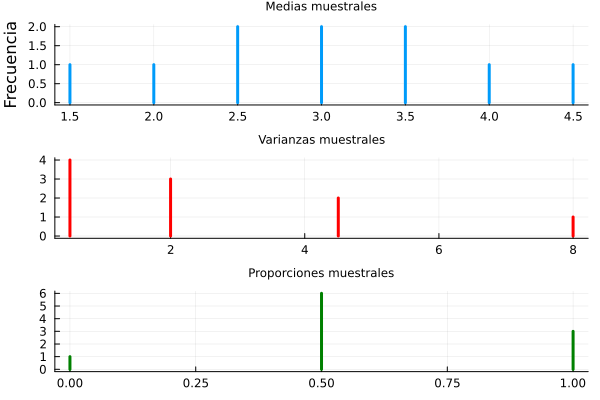

In [22]:
p1 = plot([1.5,2,2.5,3,3.5,4,4.5,], tm, st=:sticks, lw=3, ylabel="Frecuencia", xguidefontsize=8)
p2 = plot([0.5,2,4.5,8], tv, st=:sticks, lw=3, color=:red)
p3 = plot([0,0.5,1],tp, st=:sticks, lw=3, color=:green)
plot(p1,p2,p3, layout=(3,1), titlefontsize=8,legend=false, title=["Medias muestrales" "Varianzas muestrales" "Proporciones muestrales"])

### Factor de corrección para poblaciones finitas

In [23]:
fc=(N-n)/(N-1)

0.75

$\sigma^2_{\bar{X}}$

In [24]:
σ²/n*fc 

0.75

$\sigma^2_{p}$

In [25]:
π*(1-π)/n*fc

0.09

$\mu_{S^2}$

In [26]:
N/(N-1)*σ²

2.5

## Un caso más grande

Con una población de tamaño $N=60$ y sacando muestras de tamaño $n=4$, se obtienen 487 635 muestras.

In [27]:
nm= binomial(60,4)

487635

In [28]:
using Distributions, StatsPlots
pobla = randn(60) .*20 .+ 50 # población
tammu=4   #  tamaño de muestra
muestras1 = combinations(pobla, tammu);
@time medias_mu = mean.(muestras1);


  0.158529 seconds (1.18 M allocations: 63.944 MiB, 32.80% gc time, 55.86% compilation time)


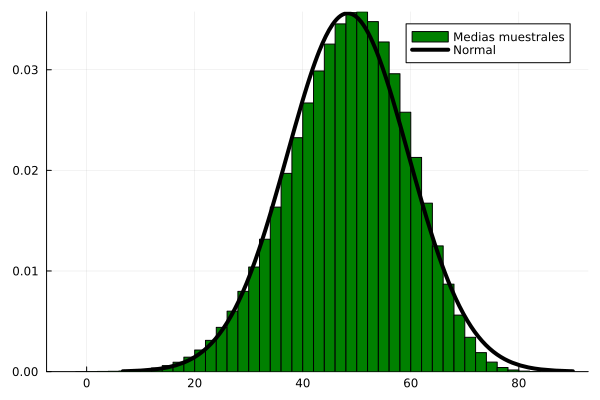

In [29]:
histogram(medias_mu, norm=true, bins=50, label="Medias muestrales", color=:green)
plot!(Normal(mean(pobla),std(pobla, corrected=false)/sqrt(tammu)), lw=4, color=:black, label="Normal",fillalpha=0.3)

In [30]:
@time varianzas_mu = var.(muestras1);

  0.053688 seconds (1.06 M allocations: 56.737 MiB, 31.21% gc time, 48.13% compilation time)


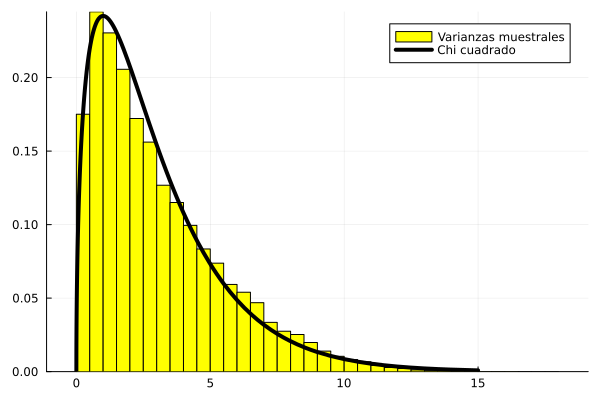

In [31]:
histogram((tammu-1)*varianzas_mu/var(pobla,corrected=false), norm=true, bins=50, label="Varianzas muestrales", color=:yellow)
plot!(Chisq(tammu-1),0,15, lw=4, color=:black, label="Chi cuadrado",fillalpha=0.3)

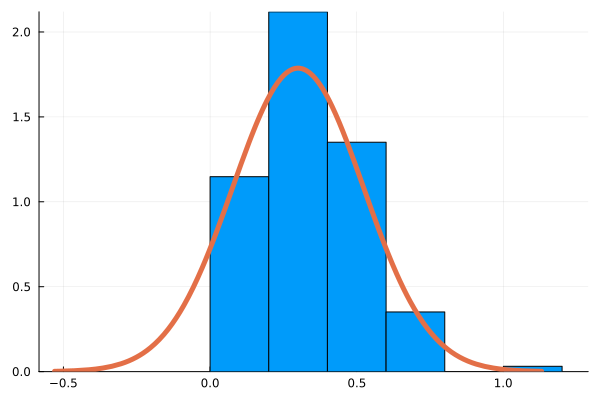

In [32]:
mprop = collect(muestras1)
props = [sum(mprop[i].<40)/tammu for i in 1:(nm)]
histogram(props,bins=6,normalize=true, leg=false)
plot!(Normal(mean(props),std(props,corrected=false)),lw=5)


In [33]:
typeof(medias_mu)

Vector{Float64} (alias for Array{Float64, 1})

## Teorema del límite central

Sea una población de tamaño $N$ con media $\mu$ y varianza $\sigma^2$, si de esta población se extraen todas las muestras de tamaño $n$ sin orden y sin reemplazo y se calculan sus medias, éstas conforman una población de medias muestrales con distribución aproximadamente normal con media 
$\mu_{\bar{X}}=\mu$ y varianza $\sigma^2_{\bar{X}}=\displaystyle\frac{\sigma^2}{n}\frac{N-n}{N-1}$ a medida que n crece.

El factor $\displaystyle\frac{N-n}{N-1}$ se llama *factor de corrección para poblaciones finitas*, se puede omitir cuando:

1. $N >> n$
2. $N \to \infty$


Puesto que 
 $$\displaystyle\lim_{N \to \infty} \frac{N-n}{N-1}=1$$

## Otros resultados

1. Sea una población normal con media $\mu$ y varianza $\sigma^2$, si de esta población se extraen todas las muestras de tamaño $n$ sin orden y sin reemplazo y se calculan sus medias, éstas conforman una población de medias con distribución normal con media $\mu_{\bar{X}}=\mu$ y varianza $\sigma^2_{\bar{X}}=\displaystyle\frac{\sigma^2}{n}$.
   
2. Sea una población de tamaño $N$ con una proporción de elementos  $\pi$, si de esta población se extraen todas las muestras de tamaño $n$ sin orden y sin reemplazo y se calculan sus proporciones, éstas conforman una población de proporciones con distribución aproximadamente normal con media $\mu_{\bar{X}}=\mu$ y varianza $\sigma^2_{\bar{X}}=\displaystyle\frac{\sigma^2}{n}\frac{N-n}{N-1}$ a medida que n crece.

3. Sea una población normal con media $\mu$ y varianza $\sigma^2$, si de esta población se extraen todas las muestras de tamaño $n$ sin orden y sin reemplazo y se calculan sus varianzas, éstas conforman una población de varianzas muestrales con distribución $\chi^2$ de tal forma que:
   
$$\chi^2_{(n-1)}=\frac{(n-1)S^2}{\sigma^2}$$


![Fórmulas DM](FormulasDM.png)

## Ejercicios

### 7.9

Cuando un proceso de producción funciona correctamente, el número de unidades producidas por hora sigue una distribución normal que tiene una media de 92.0 y una desviación típica de 3.6. Se ha tomado una muestra aleatoria de cuatro horas distintas. 

1. Halle la media de la distribución de las medias muestrales en el muestreo.

2. Halle la varianza de la media muestral.

3. Halle el error típico de la media muestral.

4. ¿Cuál es la probabilidad de que la media muestral sea de más de 93.0 unidades?

Nos dan $\mu=92$, $\sigma=3.6$ y $n=4$

1. $$\mu_{\bar{X}}=\mu=92$$

2. $$\sigma^2_{\bar{X}}=\frac{\sigma^2}{n}=\frac{3.6^2}{4}=3.24$$

3. $$\sigma_{\bar{X}}=\sqrt{3.24}=1.8$$

4. $$P(\bar{X} > 93)= 0.2893  $$


In [34]:
μ₁=92
σ₁=3.6
n₁=4
println( "a) ", μ₁)

a) 92


In [35]:
VM=σ₁^2/n₁
println("b) ", VM)


b) 3.24


In [36]:
println("c) ", √(VM))

c) 1.8


In [37]:
println("d) ",ccdf(Normal(μ₁,√(VM)),93))

d) 0.28925736075397196


In [38]:
round(ℯ,digits=10)

2.7182818285

### 7.23

Una ciudad tiene 500 agencias inmobiliarias. El valor medio de las propiedades vendidas en un año por estas agencias es de 800000 pesos y la desviación típica es de 300000 pesos. Se selecciona una muestra aleatoria de 100 agencias y se anota el valor de las propiedades que venden en un año.

1. ¿Cuál es el error típico de la media muestral?

2. ¿Cuál es la probabilidad de que la media muestral sea de más de 825000 pesos?

3. ¿Cuál es la probabilidad de que la media muestral sea de más de 780000 pesos?

4. ¿Cuál es la probabilidad de que la media muestral esté comprendida entre 790.000 y 820000 pesos?

 Nos dan   $N=500$, $\mu=800000$, $\sigma=300000$ y $n=100$

In [39]:
fc1=sqrt((500-100)/(500-1))
σ= 300000/sqrt(100)*fc1

26859.688862150713

$P(\bar{X} >825000)$

In [40]:
ccdf(Normal(800_000,σ),825_000)

0.1759881306261567

In [41]:
ccdf(Normal(800_000,σ),780_000)

0.7717463192252952

In [42]:
cdf(Normal(800_000,σ),820_000)-cdf(Normal(800_000,σ),790_000)

0.41691348009790197

### 7.44

Una pequeña universidad tiene 528 alumnos de primer curso, de los cuales 211 llevan su propio
ordenador personal al campus. Se ha tomado una muestra aleatoria de 120 estudiantes de primer
curso.

1. ¿Cuál es el error típico de la proporción muestral que lleva su propio ordenador personal al campus?

2. ¿Cuál es la probabilidad de que la proporción muestral sea de menos de 0.33?

3. ¿Cuál es la probabilidad de que la proporción muestral esté comprendida entre 0.5 y 0.6?

Tenemos N=528, $\pi_1=\frac{211}{528}$, n=120

In [43]:
n=120
π₁=211/528
N=528
σₚ=sqrt(π₁*(1-π₁)/n)*sqrt((N-n)/(N-1))

0.03934332742081992

P( p < 0.33)=

In [44]:
cdf(Normal(π₁,σₚ),0.33 )

0.038398467387429594

In [45]:
cdf(Normal(π₁,σₚ),0.6)-cdf(Normal(π₁,σₚ),0.5)

0.005365074912874301

### 7.53

Se va a realizar a todos los estudiantes de primer año un examen de matemáticas con 100 preguntas de tipo test. Se ha hecho primero un estudio piloto en el que se ha realizado el examen a una muestra aleatoria de 20 estudiantes de primer año. Suponga que la distribución del número de respuestas correctas de la población de todos los estudiantes de primer año es normal con una varianza de 250.

1. ¿Cuál es la probabilidad de que la varianza muestral sea inferior a 100?

2. ¿Cuál es la probabilidad de que la varianza muestral sea superior a 500?

n=20, $\sigma^2=250$, $P(S^2 < 100)=P(\chi^2_{(19)} < \frac{(20-1)100}{250})$

In [46]:
cdf(Chisq(19),(20-1)*100/250)

0.009737257060592967

In [47]:
ccdf(Chisq(19),(20-1)*500/250)

0.005934709007201127

### 7.54. 

En una gran ciudad se ha observado que durante el verano las facturas del consumo de electricidad siguen una distribución normal que tiene una desviación típica de 100 pesos. Se ha tomado una muestra aleatoria de 25 facturas.

1. Halle la probabilidad de que la desviación típica muestral sea inferior a 75 pesos.

2. Halle la probabilidad de que la desviación típica muestral sea superior a 150 pesos.

$n=25$, $\sigma=100$  $P(S <75)=P(\chi^2_{(24)} < \frac{(25-1)*75^2}{100^2})$

In [48]:
cdf(Chisq(24),24*75^2/100^2)

0.042850493350583566

$P(S > 150)=P(\chi^2_{(24)}>\frac{(25-1)*150^2}{100^2})$

In [49]:
ccdf(Chisq(24),24*150^2/10062)

0.00047200678507302457

### 7.66

Las calificaciones de todos los estudiantes que realizan un examen de aptitud que se exige para entrar en una facultad de derecho siguen una distribución normal que tiene una media de 420 y una desviación típica de 100. Se toma una muestra aleatoria de 25 calificaciones.

1. Halle la probabilidad de que la media muestral de las calificaciones sea superior a 450.

2.  Halle la probabilidad de que la media muestral de las calificaciones esté comprendida entre 400 y 450.

3. La probabilidad de que la media muestral de las calificaciones sea superior a ––––––– es 0.10

4. La probabilidad de que la media muestral de las calificaciones sea inferior a ––––––– es 0.10

5.  La probabilidad de que la desviación típica muestral de las calificaciones sea superior a –––––– es 0.05

6. La probabilidad de que la desviación típica muestral de las calificaciones sea inferior a ––––––– es 0.05

7. Si se hubiera tomado una muestra de 50 calificaciones, ¿sería la probabilidad de que la media muestral de las calificaciones sea superior a 450 menor, mayor o igual que la respuesta correcta al apartado 1. ? No es necesario hacer aquí los cálculos detallados. Ilustre gráficamente su razonamiento.

Tenemos $\mu=420$, $\sigma=100$ y $n=25$  

1. $P(\bar{X} >450)$

2. $P(400 < \bar{X} <450)$

3. $P(\bar{X} > k )=0.1$

   $P(Z > \frac{k-420}{\frac{100}{\sqrt{25}}})=0.1$

In [50]:
q1 = quantile(Normal(), 0.9)

1.2815515655446004

In [51]:
q2 = cquantile(Normal(), 0.1)

1.2815515655446004

In [52]:
k = q1*(100/sqrt(25))+420

445.631031310892

5. $P(S > k )=0.05$

$P(\chi^2_{(24)}> \frac{(25-1)k^2}{100^2})=0.05$

In [53]:
q3= quantile(Chisq(24),0.95)

36.41502850180731

In [54]:
q4 = cquantile(Chisq(24), 0.05)

36.41502850180731

In [55]:
k=sqrt(q3*100^2/24)

123.17844187364814

### 7.78

Un año el 40 por ciento de las ventas de viviendas fue financiado parcialmente por el vendedor. Se examina una muestra aleatoria de 250 ventas.

1. La probabilidad de que la proporción muestral sea de más de ––––––– es 0.8

2. La probabilidad de que la proporción muestral sea de menos de –––––– es 0.9



Tenemos $\pi=0.4$ y $n=250$

1. $P(p > k)=0.8$

$P( Z > \frac{k-0.4}{\sqrt{\frac{0.4(1-0.4)}{250}}})=0.8$

In [56]:
q5 = quantile(Normal(), 0.2)

-0.8416212335729143

In [57]:
q6 = cquantile(Normal(), 0.8 )

-0.8416212335729143

In [58]:
k = q5*sqrt(0.4*0.6/250)+0.4

0.3739233198284605

In [59]:
Crayons.test_system_colors()

          black black
            red red
          green green
         yellow yellow
           blue blue
        magenta magenta
           cyan cyan
     light_gray light_gray
        default default
      dark_gray dark_gray
      light_red light_red
    light_green light_green
   light_yellow light_yellow
     light_blue light_blue
  light_magenta light_magenta
     light_cyan light_cyan
          white white


In [60]:
Crayons.test_256_colors(codes=true)

System colors (0..15):
000 001 002 003 004 005 006 007 
008 009 010 011 012 013 014 015 


Color cube, 6×6×6 (16..231):
016 017 018 019 020 021 
022 023 024 025 026 027 
028 029 030 031 032 033 
034 035 036 037 038 039 
040 041 042 043 044 045 
046 047 048 049 050 051 

052 053 054 055 056 057 
058 059 060 061 062 063 
064 065 066 067 068 069 
070 071 072 073 074 075 
076 077 078 079 080 081 
082 083 084 085 086 087 

088 089 090 091 092 093 
094 095 096 097 098 099 
100 101 102 103 104 105 
106 107 108 109 110 111 
112 113 114 115 116 117 
118 119 120 121 122 123 

124 125 126 127 128 129 
130 131 132 133 134 135 
136 137 138 139 140 141 
142 143 144 145 146 147 
148 149 150 151 152 153 
154 155 156 157 158 159 

160 161 162 163 164 165 
166 167 168 169 170 171 
172 173 174 175 176 177 
178 179 180 181 182 183 
184 185 186 187 188 189 
190 191 192 193 194 195 

196 197 198 199 200 201 
202 203 204 205 206 207 
208 209 210 211 212 213 
214 215 216 217 218 219 
220 221 222 223 224 225 


In [61]:
Crayons.test_24bit_colors(codes=false)

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████

██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
██████████████████
███████

In [62]:
printstyled("Hello\n"; color = :blue)

Hello
